In [1]:
import numpy as np
import random
import scipy.special
from scipy.special import factorial
import matplotlib.pyplot as plt
# The below commands make the font and image size bigger
plt.rcParams.update({'font.size': 18})
plt.rcParams["figure.figsize"] = (16,9)

In [2]:
k_b = 1.380649e-23                                        # Boltzmann constant for entropy calculation

# Main Program

In [3]:
def ehrenfest_model(N, t_max, t_step):
        pstate = np.zeros(N)                                        # state vector
        time_points = np.arange(0, t_max, t_step)                   # x-axis for plotting
        left_points = []                                            # empty array for left y-values
        right_points = []                                           # empty array for right y-values
        entropy = []                                                # I <3 Boltzmann

        for i in range(t_max):
    
            n = np.count_nonzero(pstate == 0)                       # checks # particles on the left
            n_right = np.count_nonzero(pstate)                      # checks # particles on the right
            e_coeff =  scipy.special.binom(N, n)                    # multiplicity of states
    
            left_points.append(n)                                   # tracks # articles on left at each timestep
            right_points.append(n_right)                            # tracks # particles on right
            entropy.append(e_coeff)                                 # track multiplicity  
    
            rnd = np.random.choice(N)                               # selects a random particle

            if pstate[rnd] == 0:                                    # Are you on the left? 
                pstate[rnd] = 1                                     # Then move right!
            else:
                pstate[rnd] = 0                                     # If you were on the right, move left!

        return n, n_right, time_points, left_points, right_points, N, entropy

# Data Runs

In [4]:
N = 800
t_max = N*50
t_step = 1

n, n_right, time_points, left_points, right_points, N, entropy = ehrenfest_model(N, t_max, t_step)
steady_state = np.array(left_points[3*N:])

The average number of particles on the left in steady-state is: 397.1
The variance of the particles on the left in the steady-state is: 159.1855319148936
The standard deviation of the particles on the left in steady-state is: 12.616874887027041
The relative magnitude of fluctuations is: 0.03177253811892984
The max deviation = 49.0


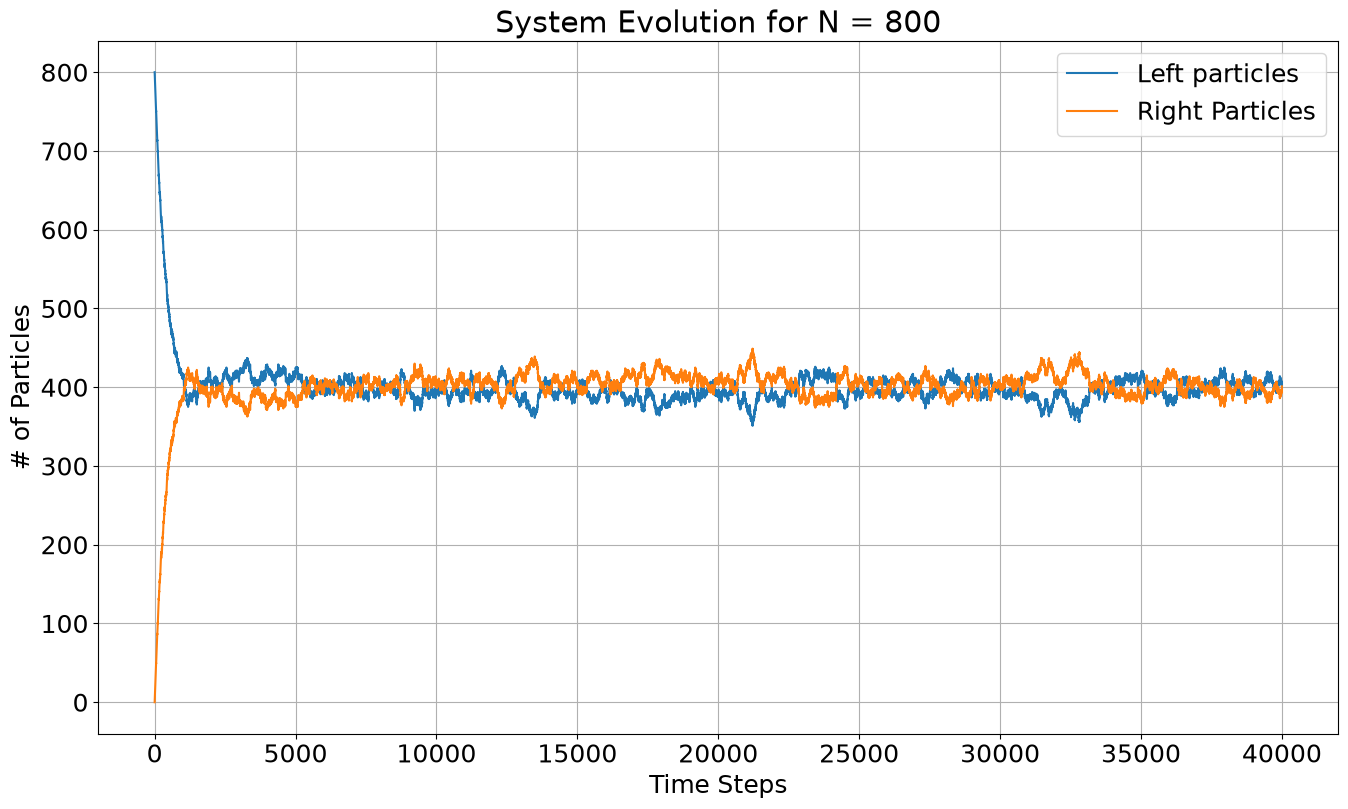

In [5]:
print("The average number of particles on the left in steady-state is:", np.mean(steady_state))
print("The variance of the particles on the left in the steady-state is:", np.var(steady_state))
print("The standard deviation of the particles on the left in steady-state is:", np.std(steady_state))
fluctuation_magnitude = np.std(steady_state) / np.mean(steady_state)
print("The relative magnitude of fluctuations is:", fluctuation_magnitude)

deviations = np.abs(steady_state - N/2)
max_deviation = np.max(deviations)
#print(deviations)
print("The max deviation =", max_deviation)

plt.plot(time_points, left_points)
plt.plot(time_points, right_points)
plt.grid(True)
plt.xlabel('Time Steps')
plt.ylabel('# of Particles')
plt.title(f"System Evolution for N = {N}")
plt.legend(['Left particles', 'Right Particles'])
plt.savefig(f"n_{N}.jpg")

In [6]:
# Find equilibrium points
left_points_eqm = np.array(left_points)
right_points_eqm = np.array(right_points)

eqm_point = np.where(left_points_eqm == right_points_eqm)[0]
print(eqm_point[0])

1064


# Monty (python) Carlo Trials

In [8]:
# Monte Carlo trials
n_trials = 100
N = 800
t_max = N*12
t_step = 1
results_left = []
results_right = []

for trial in range(n_trials):
    n, n_right, time_points, left_points, right_points, N, entropy = ehrenfest_model(N, t_max, t_step)
    results_left.append(left_points)
    results_right.append(right_points)

In [9]:
# Convert to arrays for processing
results_left = np.array(results_left)
ss_mc = results_left[:, 5*N:]
#print(np.size(results_left))
#print(np.shape(results_left))
#print(np.mean(results_left))
#print(ss_mc)

# This is my full array for plotting
mean_results_l = np.mean(results_left, axis=0)

# Statistics
print(np.mean(ss_mc))
print(np.var(ss_mc))
print(np.std(ss_mc))
print(np.std(ss_mc) / np.mean(ss_mc))

400.02331428571426
193.86979215836732
13.923713303510933
0.03480725449308688


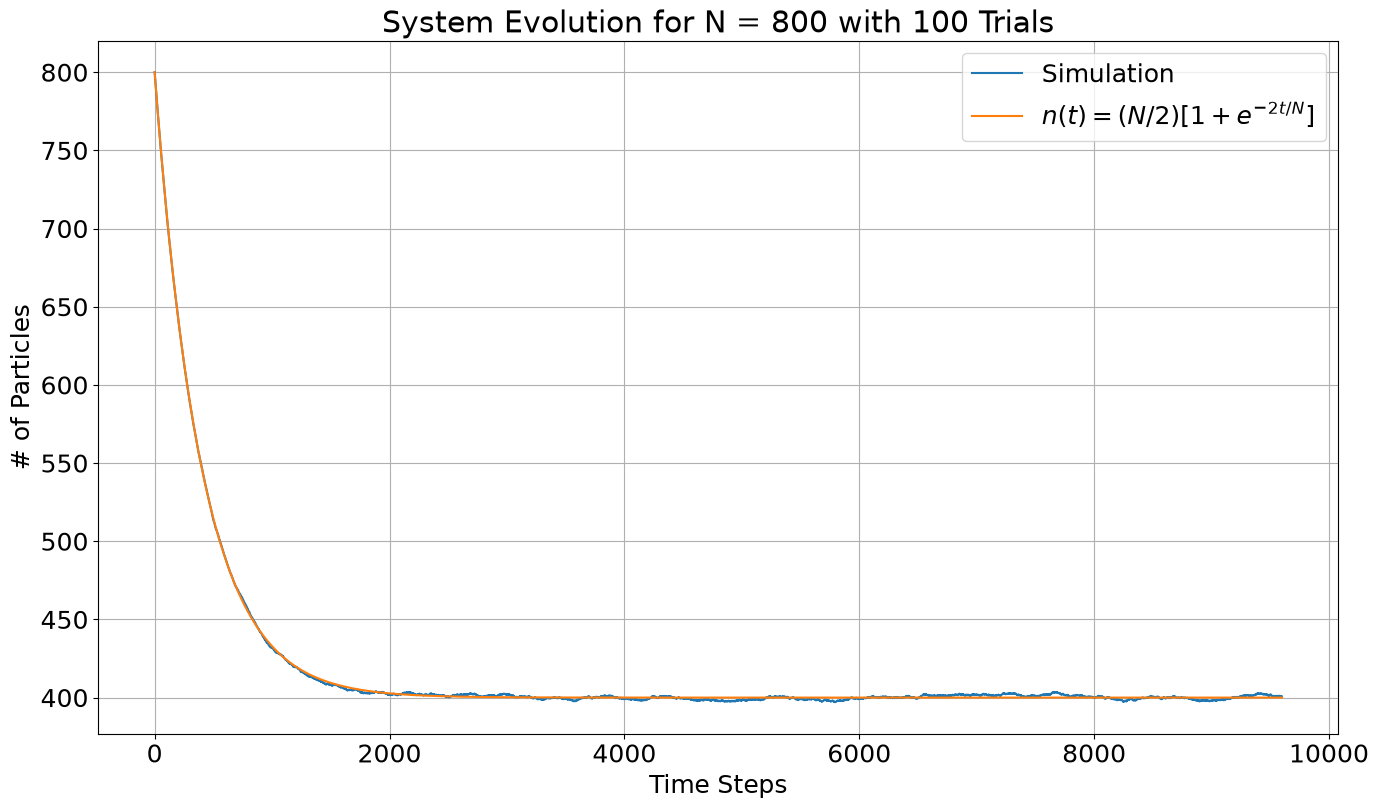

In [10]:
plt.plot(time_points, mean_results_l)
#plt.plot(time_points, mean_results_r)
plt.plot(time_points, (N / 2) * (1 + np.exp((-2*time_points) / N)))
plt.grid(True)
plt.xlabel('Time Steps')
plt.ylabel('# of Particles')
plt.title(f"System Evolution for N = {N} with {n_trials} Trials")
plt.legend(['Simulation', '$n(t) = (N/2)[ 1 + e^{-2t/N}]$'])
plt.savefig(f"MC_n_{N}_t{n_trials}.jpg")

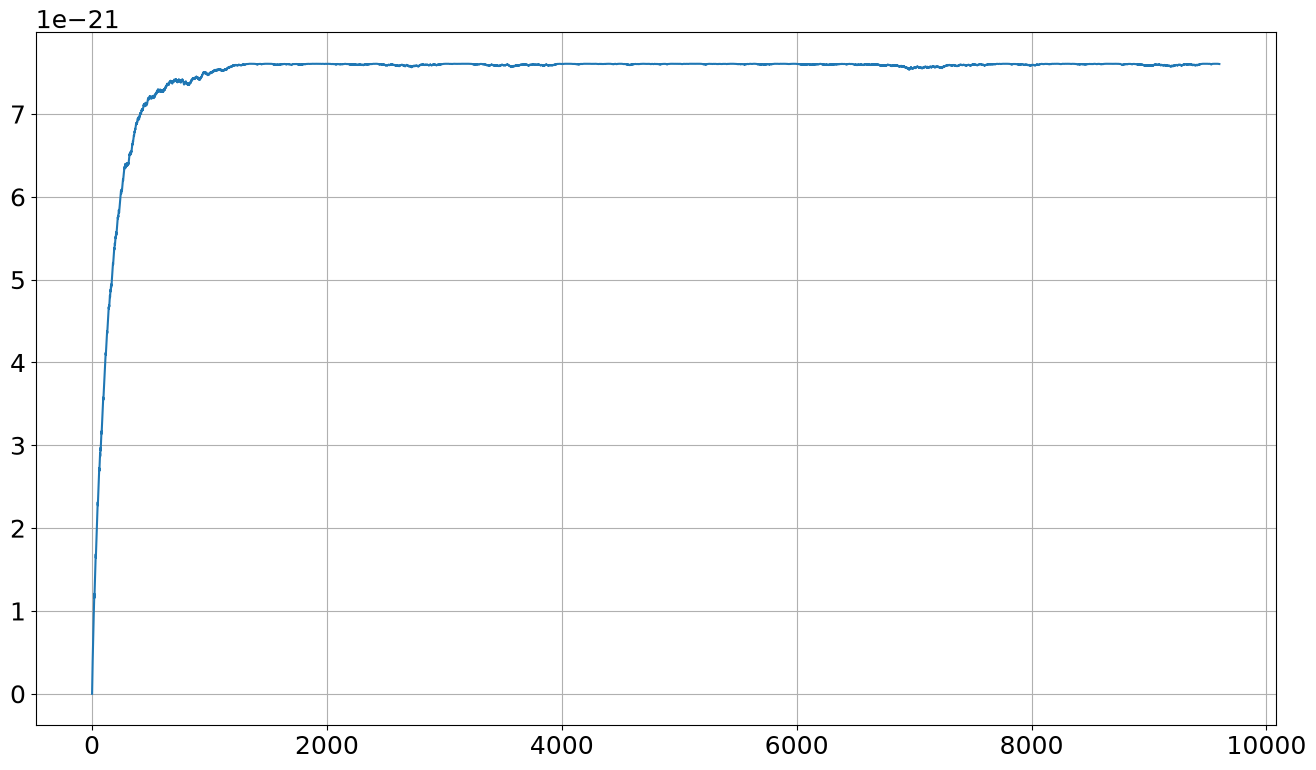

In [11]:
plt.plot(time_points, (k_b * np.log(entropy)))
plt.grid(True)